# Case study: HeLa tunicamycin (UPR)

HeLa cells treated with tunicamycin: 3′ RNA response and a single-cell unfolded-protein-response score.

This case study examines one public SpatialData object (SDO): contents, assays and panels,
plate layout, per-cell tables, and an experiment-specific analysis.

**Prerequisites.** Install the package and JupyterLab ([installation guide](../../docs/installation.md)).
[`GettingStarted.ipynb`](../GettingStarted.ipynb) covers loading an SDO and reading its tables.

**Data.** **Cytos-3Prime_HeLa-Tunicamycin** (~87.5 GB). Streams from public S3 by default; an optional local download
is described in section 0. No AWS credentials are required.


## 0. Access the data

Dataset: **Cytos-3Prime_HeLa-Tunicamycin** (~87.5 GB).

### Default: stream from public S3

The next cell opens the public `spatialdata/` prefix with `storage_options={"anon": True}`.
`Loader` reads tables and metadata remotely; image pyramids and molecule points stay on S3.

### Optional: local download

Download the archive when you need image pyramids, segmentation masks, or other pixel-level work.
Run the commands below from the **`tutorials/`** directory so the file is written to
`tutorials/data/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip`, then uncomment the local-override lines in the next cell
(`SDO_PATH = "../data/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip"` and `STORAGE_OPTIONS = {}`).

**Option A: `curl`**

```bash
mkdir -p data
curl -C - -L -o data/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip \
  "https://element-public-data.s3.us-west-2.amazonaws.com/Cytos/elembio-multiomics/Cytos-3Prime_HeLa-Tunicamycin/cb6f3a2ebb6c43acac4ad08b2b2a7779/spatialdata/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip"
```

If the download stops, run the same command again to resume. On Windows PowerShell, use `curl.exe`.

**Option B: AWS CLI**

```bash
mkdir -p data
aws s3 cp \
  s3://element-public-data/Cytos/elembio-multiomics/Cytos-3Prime_HeLa-Tunicamycin/cb6f3a2ebb6c43acac4ad08b2b2a7779/spatialdata/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip \
  data/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip \
  --no-sign-request
```

Do not unzip the archive; `Loader` reads `.zarr.zip` directly.


In [1]:
%matplotlib inline
import warnings

import fsspec
import numpy as np
import pandas as pd
import s3fs
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Markdown, display

from elembio_spatialdata_analysis.load import Loader

# Quiet known library noise (matmul / overflow RuntimeWarnings from DESeq2 fits).
warnings.filterwarnings("ignore", message="Did not read zarr as consolidated")
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"sklearn\..*")
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"pydeseq2\..*")
warnings.filterwarnings(
    "ignore",
    message=r".*encountered in matmul",
    category=RuntimeWarning,
)

# ---- default: stream from the public spatialdata/ prefix ----
SPATIALDATA_PREFIX = (
    "s3://element-public-data/Cytos/elembio-multiomics/Cytos-3Prime_HeLa-Tunicamycin/cb6f3a2ebb6c43acac4ad08b2b2a7779/spatialdata"
)
STORAGE_OPTIONS = {"anon": True}

# Optional local override (after downloading into tutorials/data/):
# SDO_PATH = "../data/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip"
# STORAGE_OPTIONS = {}

fs = s3fs.S3FileSystem(**STORAGE_OPTIONS)
prefix_key = SPATIALDATA_PREFIX.removeprefix("s3://").rstrip("/")


def human_size(n: int) -> str:
    if n >= 1e9:
        return f"{n / 1e9:.2f} GB"
    if n >= 1e6:
        return f"{n / 1e6:.1f} MB"
    return f"{n / 1e3:.1f} kB"


def list_objects(key: str) -> pd.DataFrame:
    """Real objects directly under an S3 prefix, dropping directory markers."""
    columns = ["name", "size", "size_bytes", "uri"]
    try:
        entries = fs.ls(key, detail=True)
    except FileNotFoundError:
        return pd.DataFrame(columns=columns)
    rows = [
        {
            "name": entry["name"].rsplit("/", 1)[-1],
            "size": human_size(entry["size"]),
            "size_bytes": entry["size"],
            "uri": "s3://" + entry["name"],
        }
        for entry in entries
        if entry["type"] == "file" and entry["name"].rsplit("/", 1)[-1]
    ]
    return pd.DataFrame(rows, columns=columns).sort_values("size_bytes", ascending=False).reset_index(drop=True)


if "SDO_PATH" not in globals():
    prefix_objects = list_objects(prefix_key)
    sdo_candidates = prefix_objects.loc[prefix_objects["name"].str.endswith(".zarr.zip")]
    if len(sdo_candidates) != 1:
        raise RuntimeError(
            f"Expected exactly one *.zarr.zip under {SPATIALDATA_PREFIX}, found {len(sdo_candidates)}."
        )
    SDO_PATH = sdo_candidates["uri"].iloc[0]
    display(Markdown("### Objects in the public prefix"))
    display(prefix_objects[["name", "size"]])
    print("SDO:    ", SDO_PATH)
    print("access: anonymous (public bucket)")

loader = Loader(SDO_PATH, storage_options=STORAGE_OPTIONS)
run = next(iter(loader._runs.values()))
print(loader.summary())


### Objects in the public prefix

,name,size
0,Cytos-3Prime_HeLa-Tunicamycin.zarr.zip,87.49 GB
1,points-zarr.zip,4.02 GB
2,cell-shapes-zarr.zip,53.9 MB
3,nuclear-shapes-zarr.zip,19.0 MB
4,cyto.viz,14.3 MB
5,Cytos-3Prime_HeLa-Tunicamycin.zarr-index.bin,874.1 kB
6,Cytos-3Prime_HeLa-Tunicamycin.points-zarr-inde...,0.3 kB
7,Cytos-3Prime_HeLa-Tunicamycin.nuclear-shapes-z...,0.1 kB
8,Cytos-3Prime_HeLa-Tunicamycin.cell-shapes-zarr...,0.1 kB


SDO:     s3://element-public-data/Cytos/elembio-multiomics/Cytos-3Prime_HeLa-Tunicamycin/cb6f3a2ebb6c43acac4ad08b2b2a7779/spatialdata/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip
access: anonymous (public bucket)


--- Cytos-3Prime_HeLa-Tunicamycin ---
  run_name:       Cytos-3Prime_HeLa-Tunicamycin
  source:         s3://element-public-data/Cytos/elembio-multiomics/Cytos-3Prime_HeLa-Tunicamycin/cb6f3a2ebb6c43acac4ad08b2b2a7779/spatialdata/Cytos-3Prime_HeLa-Tunicamycin.zarr.zip
  tables:         ['ThreePrimeUntargeted', 'imaging']
  batches (7):   B01 (ThreePrimeUntargeted), B02 (ThreePrimeUntargeted), B03 (ThreePrimeUntargeted), B04 (ThreePrimeUntargeted), B05 (ThreePrimeUntargeted), CP01 (PreAmp), P01 (PreAmp)
  wells (12):     A1, A2, B1, B2, C1, C2, D1, D2, ... (12 total)
  tiles:          144
  points:         60 elements (well mode)
  build:          1.0.0rc15


## 1. What is inside the SDO

The archive is a SpatialData Zarr store with five kinds of element:

| Element | Contents | Opened with |
|---|---|---|
| Tables | Per-cell AnnData, one per assay | `Loader.load_tables` |
| Points | Per-molecule / polony locations | `Loader.load_points` |
| Images | Multiscale pixel pyramids | `spatialdata.read_zarr` (directory store) |
| Labels | Segmentation masks | `spatialdata.read_zarr` |
| Shapes | Vector segmentation boundaries | `spatialdata.read_zarr` |

How the tables are organized:

- **Imaging is one table holding two assays.** Morphology (CellPaint) stains and protein
  immunofluorescence markers are measured on the same cells and stored together in the
  `imaging` table, separated by `target_type`.
- **Table names come from the run.** An OPS / identity panel name includes a run-specific
  suffix. Imaging appears as `imaging` (or the legacy alias `CellPaint`).

`Loader` reads the archive index and tables remotely. Image and segmentation work
requires a local directory store or mount and is covered separately.


In [2]:
# Which target_type each loadable table belongs to.
types_by_table: dict[str, set[str]] = {}
for target_type in sorted(loader.available_target_types):
    for suffix in run.table_suffixes_for_target_type((target_type,)):
        types_by_table.setdefault(suffix, set()).add(target_type)

CONTENTS_BY_TYPE = {
    "OPS": "identity or control panel",
    "SpecializedTargeted": "identity or control panel",
    "ThreePrimeUntargeted": "3′ RNA counts",
    "imaging": "morphology + protein IF",
}

tables = pd.DataFrame(
    [
        {
            "table": name,
            "target_type": ", ".join(sorted(types_by_table.get(name, {"(unlabelled)"}))),
            "contents": " / ".join(
                dict.fromkeys(
                    CONTENTS_BY_TYPE.get(t, "see metadata")
                    for t in sorted(types_by_table.get(name, []))
                )
            )
            or "see metadata",
        }
        for name in sorted(loader.available_tables)
    ]
)
display(Markdown("### Analysis tables in this SDO"))
display(tables)


def spatial_element_inventory(sdo_uri: str, storage_options: dict) -> pd.DataFrame:
    """Count SpatialData elements from the archive index — no pixel data is fetched."""
    if str(sdo_uri).startswith("s3://"):
        archive = fsspec.filesystem(
            "zip", fo=sdo_uri, target_protocol="s3", target_options=storage_options
        )
    else:
        archive = fsspec.filesystem("zip", fo=sdo_uri)
    roots = [
        str(e).rstrip("/")
        for e in archive.ls("/", detail=False)
        if str(e).rstrip("/").endswith(".zarr")
    ]
    if len(roots) != 1:
        raise RuntimeError(f"Expected one *.zarr root inside the archive, found {roots}.")
    root = roots[0]

    rows = []
    for element in ("tables", "images", "labels", "shapes", "points"):
        try:
            entries = archive.ls(f"{root}/{element}", detail=False)
        except FileNotFoundError:
            entries = []
        names = sorted(
            n
            for n in (str(x).rsplit("/", 1)[-1] for x in entries)
            if n and not n.endswith(".json")
        )
        rows.append({"element": element, "count": len(names), "examples": ", ".join(names[:2])})
    return pd.DataFrame(rows)


elements = spatial_element_inventory(SDO_PATH, STORAGE_OPTIONS)
display(Markdown("### All elements stored in the archive"))
display(elements)

n_archive_tables = int(elements.loc[elements["element"].eq("tables"), "count"].iloc[0])
print(
    f"{n_archive_tables} table groups in the archive vs {len(loader.available_tables)} loadable assay tables — "
    "the extra one is global-table-metadata (wells, tiles, batches, targets)."
)


### Analysis tables in this SDO

,table,target_type,contents
0,ThreePrimeUntargeted,ThreePrimeUntargeted,3′ RNA counts
1,imaging,imaging,morphology + protein IF


### All elements stored in the archive

,element,count,examples
0,tables,3,"global-table-ThreePrimeUntargeted, global-tabl..."
1,images,12,"A1-images-cell_paint, A2-images-cell_paint"
2,labels,24,"A1-labels-Cell, A1-labels-Nuclear"
3,shapes,24,"A1-shapes-Cell, A1-shapes-Nuclear"
4,points,60,"A1-points-B01, A1-points-B02"


3 table groups in the archive vs 2 loadable assay tables — the extra one is global-table-metadata (wells, tiles, batches, targets).


## 2. Which assays were run, and what panels

Run metadata splits what the compact table names hide:

- `run.targets_imaging` separates CellPaint morphology stains from Protein IF markers.
- Panel metadata distinguishes cell-assigning identity panels from untargeted 3′ RNA,
  and flags control panels with `IsControl`.

**`control_type` — what it means.** A few channels exist to validate the assay:

| `control_type` | Role |
|---|---|
| `Positive…` | Expected to stain strongly in every cell. Weak signal flags a staining or imaging problem |
| `Negative…` | Antibody isotype controls (IgG); a floor for non-specific binding |
| empty | An ordinary readout — most of the panel |

Isotype and background channels are usually excluded from profiling matrices used for embeddings.


In [3]:
imaging_targets = run.targets_imaging.copy()
diss_targets = run.diss_targets_metadata.copy()


def as_bool(series: pd.Series) -> pd.Series:
    """Metadata booleans arrive as bool, string, or NaN depending on build version."""
    return series.astype(str).str.lower().isin({"true", "1", "yes"})


def control_role(value: object) -> str:
    text = "" if value is None else str(value).strip()
    if text.lower().startswith("positive"):
        return "positive staining control"
    if text.lower().startswith("negative"):
        return "isotype control"
    return "readout"


morphology_panel = imaging_targets.loc[imaging_targets["target_type"].eq("CellPaint")].copy()
protein_panel = imaging_targets.loc[imaging_targets["target_type"].eq("ProteinIF")].copy()
for panel in (morphology_panel, protein_panel):
    panel["role"] = panel["control_type"].map(control_role)

assigns_cells = as_bool(diss_targets["CellAssignment"])
is_control = (
    as_bool(diss_targets["IsControl"])
    if "IsControl" in diss_targets.columns
    else pd.Series(False, index=diss_targets.index)
)
identity_sites = diss_targets.loc[assigns_cells & ~is_control, "TargetSiteName"].tolist()
control_sites = diss_targets.loc[assigns_cells & is_control, "TargetSiteName"].tolist()
untargeted = diss_targets.loc[~assigns_cells]
untargeted_batches = sorted(untargeted["batch_name"].unique()) if "batch_name" in untargeted else []

rows = []
if identity_sites:
    rows.append(("Identity / OPS panel", ", ".join(identity_sites), "assigns each cell to a library member"))
if control_sites:
    rows.append(("Control panel", ", ".join(control_sites), "diagnostic when identity counts come out low"))
if untargeted_batches:
    rows.append((
        "3′ untargeted RNA",
        f"{len(untargeted_batches)} batches ({len(untargeted)} RT target sites)",
        "per-cell transcript counts",
    ))
if len(morphology_panel):
    rows.append(("CellPaint morphology", f"{len(morphology_panel)} stains", "intensity, localisation, CellProfiler features"))
if len(protein_panel):
    n_readout = int(protein_panel["role"].eq("readout").sum())
    n_isotype = int(protein_panel["role"].eq("isotype control").sum())
    rows.append(("Protein IF", f"{n_readout} markers + {n_isotype} isotype controls", "protein abundance and localisation"))

display(Markdown("### Assays present, from run metadata"))
display(pd.DataFrame(rows, columns=["assay", "panel", "readout"]))

panel_columns = ["target_name", "role", "control_type", "batch_name"]
if len(morphology_panel):
    display(Markdown("### CellPaint / morphology panel"))
    display(morphology_panel[panel_columns].reset_index(drop=True))
if len(protein_panel):
    display(Markdown("### Protein IF panel"))
    display(protein_panel[panel_columns].reset_index(drop=True))

print(f"wells: {len(run.wells)}   tiles: {len(run.tiles)}")
print("imaging batches:", sorted(imaging_targets["batch_name"].unique()))


### Assays present, from run metadata

,assay,panel,readout
0,3′ untargeted RNA,5 batches (5 RT target sites),per-cell transcript counts
1,CellPaint morphology,4 stains,"intensity, localisation, CellProfiler features"
2,Protein IF,12 markers + 2 isotype controls,protein abundance and localisation


### CellPaint / morphology panel

,target_name,role,control_type,batch_name
0,Mitochondria,positive staining control,Positive1,CP01
1,Cell-Membrane,readout,,CP01
2,Nucleus,readout,,CP01
3,Actin,readout,,CP01


### Protein IF panel

,target_name,role,control_type,batch_name
0,Mouse_IgG,isotype control,Negative1,P01
1,Rabbit_IgG,isotype control,Negative2,P01
2,GM130,readout,,P01
3,ERp57,readout,,P01
4,Alpha-tubulin,readout,,P01
5,LAMP-2,readout,,P01
6,LaminA_LaminC,readout,,P01
7,Histone,readout,,P01
8,Beta-Actin,readout,,P01
9,Na-K-ATPase,readout,,P01


wells: 12   tiles: 144
imaging batches: ['CP01', 'P01']


## 3. Plate layout

Well identity and labels come from run metadata (`run.wells`).

Two fields to know:

- **`cell_type`** is the segmentation model used to find cells (chosen for nuclear and cell size).
  That name often differs from the biological sample.
- **`well_label`** is free text set at run configuration. The schematic colours wells by the
  stored label. Mapping those strings to treatment, dose, timepoint, or replicate is part of
  interpreting the experiment.


### Wells as stored in run metadata

,well_name,well_label,cell_type,well_layout,target_site_names
0,A1,Hela,HELA,TwelveWellStandard,
1,A2,Hela2ugTun,HELA,TwelveWellStandard,
2,B1,HelaDMSO,HELA,TwelveWellStandard,
3,B2,Hela1ugTun,HELA,TwelveWellStandard,
4,C1,Hela2ugTun,HELA,TwelveWellStandard,
5,C2,Hela,HELA,TwelveWellStandard,
6,D1,Hela1ugTun,HELA,TwelveWellStandard,
7,D2,HelaDMSO,HELA,TwelveWellStandard,
8,E1,Hela,HELA,TwelveWellStandard,
9,E2,Hela2ugTun,HELA,TwelveWellStandard,


cell_type holds segmentation model(s): ['HELA']
distinct well_label values: ['Hela', 'Hela1ugTun', 'Hela2ugTun', 'HelaDMSO']


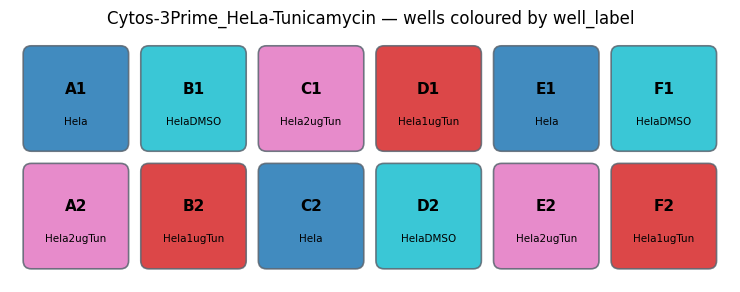

In [4]:
wells = run.wells.copy()
if wells.empty:
    raise RuntimeError("Run metadata carries no wells table — this store has no global-table-metadata.")
if "well_name" not in wells.columns:
    wells = wells.reset_index().rename(columns={wells.index.name or "index": "well_name"})
wells["well_name"] = wells["well_name"].astype(str)

shown = [c for c in ("well_name", "well_label", "cell_type", "well_layout", "target_site_names") if c in wells.columns]
display(Markdown("### Wells as stored in run metadata"))
display(wells[shown].sort_values("well_name").reset_index(drop=True))
if "cell_type" in wells.columns:
    print("cell_type holds segmentation model(s):", sorted(wells["cell_type"].astype(str).unique()))
print("distinct well_label values:", sorted(wells["well_label"].astype(str).unique()))

# Grid derived from the well names themselves, e.g. "C2" -> column C, row 2.
parsed = wells["well_name"].str.extract(r"^(?P<col>[A-Za-z]+)(?P<row>\d+)$")
if parsed.isna().any().any():
    raise RuntimeError("Unexpected well naming; cannot derive a plate grid.")
wells = pd.concat([wells, parsed], axis=1)
columns = sorted(wells["col"].unique())
rows = sorted(wells["row"].unique(), key=int)

labels = sorted(wells["well_label"].astype(str).unique())
palette = plt.get_cmap("tab10", max(len(labels), 1))
label_colors = {label: palette(i) for i, label in enumerate(labels)}

fig, ax = plt.subplots(figsize=(1.55 * len(columns), 1.8 * len(rows)))
side, gap = 1.0, 0.16
for ci, col in enumerate(columns):
    for ri, row in enumerate(rows):
        record = wells.loc[(wells["col"] == col) & (wells["row"] == row)]
        if record.empty:
            continue
        label = str(record["well_label"].iloc[0])
        x, y = ci * (side + gap), (len(rows) - 1 - ri) * (side + gap)
        ax.add_patch(
            FancyBboxPatch(
                (x, y), side, side,
                boxstyle="round,pad=0.02,rounding_size=0.08",
                facecolor=label_colors[label], edgecolor="#5A6570", linewidth=1.2, alpha=0.85,
            )
        )
        ax.text(x + side / 2, y + side * 0.6, f"{col}{row}", ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + side / 2, y + side * 0.28, label, ha="center", va="center", fontsize=7.5)
ax.set_xlim(-0.15, len(columns) * (side + gap))
ax.set_ylim(-0.15, len(rows) * (side + gap))
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"{run.run_name} — wells coloured by well_label")
plt.show()


## 4. Load the per-cell tables

Tables can be loaded lazily so matrices stay on disk until analysis needs them. All tables
share the same cells (`n_obs` matches), but **a "feature" means something different in each table**:

| Table | One feature is |
|---|---|
| 3′ untargeted | one gene model from the GENCODE annotation |
| Imaging | one measurement per cell (channel intensity, localisation ratio, or CellProfiler feature) |


In [5]:
specialized = list(run.table_suffixes_for_target_type(("OPS", "SpecializedTargeted")))
control_site_names = {name.lower() for name in control_sites}
identity_tables = [t for t in specialized if t.split("-", 1)[-1].lower() not in control_site_names]
control_tables = [t for t in specialized if t not in identity_tables]
imaging_alias = sorted({"imaging", "CellPaint"} & set(loader.available_tables))
has_three_prime = "ThreePrimeUntargeted" in loader.available_tables

identity = loader.load_tables(table=identity_tables[0], lazy=True, include_target_assignment=True) if identity_tables else None
control = loader.load_tables(table=control_tables[0], lazy=True) if control_tables else None
imaging = loader.load_tables(table="imaging", lazy=True) if imaging_alias else None
rna = loader.load_tables(table="ThreePrimeUntargeted", lazy=True) if has_three_prime else None

loaded = {}
if identity is not None:
    loaded[identity_tables[0]] = (identity, "a guide in the library")
if control is not None:
    loaded[control_tables[0]] = (control, "a control probe")
if imaging is not None:
    loaded["imaging"] = (imaging, "an imaging measurement")
if rna is not None:
    loaded["ThreePrimeUntargeted"] = (rna, "a GENCODE gene model")

display(Markdown("### Loaded tables"))
display(pd.DataFrame(
    [
        {"table": name, "cells": f"{table.n_obs:,}", "features": f"{table.n_vars:,}", "a feature is": meaning}
        for name, (table, meaning) in loaded.items()
    ]
))


### Loaded tables

,table,cells,features,a feature is
0,imaging,"150,732","1,858",an imaging measurement
1,ThreePrimeUntargeted,"150,732","54,949",a GENCODE gene model


## 5. What those features are

The same counts, broken down from each table's `var` metadata — so a large feature count becomes
something you can inspect directly.


In [6]:
def var_frame(table) -> pd.DataFrame:
    """`var` as pandas, whether the table was read lazily (Dataset2D) or eagerly (DataFrame)."""
    var = table.var
    if isinstance(var, pd.DataFrame):
        return var
    names = list(var.columns) if hasattr(var, "columns") else list(var.keys())
    return pd.DataFrame(
        {name: np.asarray(var[name]) for name in names},
        index=pd.Index(np.asarray(table.var_names), name="feature"),
    )


if identity is not None:
    library = (
        pd.Series(np.asarray(identity.var_names)).astype(str)
        .str.replace(r"_\d+$", "", regex=True)
        .value_counts().rename_axis("library_member").reset_index(name="n_guides")
    )
    display(Markdown(f"**Identity library** — {identity.n_vars} guides across {len(library)} members"))
    display(library)

if control is not None:
    control_var = var_frame(control)
    gene_column = "target_gene" if "target_gene" in control_var.columns else None
    display(Markdown(f"**Control panel** — {control.n_vars} probes"))
    display(control_var[[c for c in ("target_gene", "control_type", "batch_name") if c in control_var.columns]])

if rna is not None:
    rna_var = var_frame(rna)
    display(Markdown(f"**3′ untargeted** — {rna.n_vars:,} gene models, by annotation class"))
    if "gene_type" in rna_var.columns:
        breakdown = rna_var["gene_type"].value_counts().rename_axis("gene_type").reset_index(name="n_genes")
        display(breakdown.head(10))
        print("protein-coding genes:", int(rna_var["gene_type"].eq("protein_coding").sum()))
    if "feature" in rna_var.columns:
        print("GTF feature level:", pd.Series(rna_var["feature"]).value_counts().to_dict())

if imaging is not None:
    imaging_var = var_frame(imaging)
    display(Markdown(f"**Imaging** — {imaging.n_vars:,} measurements per cell"))
    summary = []
    GROUP_LABELS = {"base": "intensity / localisation", "cellprofiler": "CellProfiler"}
    if "feature_class" in imaging_var.columns:
        for feature_class, n in imaging_var["feature_class"].value_counts().items():
            summary.append({
                "group": GROUP_LABELS.get(feature_class, str(feature_class)),
                "n_features": int(n),
            })
    if "is_background" in imaging_var.columns:
        n_background = int(imaging_var["is_background"].astype(str).str.lower().isin({"true", "1"}).sum())
        summary.append({"group": "background (subset, excluded)", "n_features": n_background})
    display(pd.DataFrame(summary))
    geometry = imaging.obsm.get("cell_geometry")
    if geometry is not None:
        print(f"plus {geometry.shape[1]} per-cell geometry columns in obsm['cell_geometry'] (Area, AreaShape_*, …)")


**3′ untargeted** — 54,949 gene models, by annotation class

,gene_type,n_genes
0,lncRNA,34853
1,protein_coding,20063
2,transcribed_unprocessed_pseudogene,20
3,transcribed_processed_pseudogene,6
4,transcribed_unitary_pseudogene,5
5,processed_pseudogene,1
6,None,1


protein-coding genes: 20063
GTF feature level: {'gene': 54948, 'None': 1}


**Imaging** — 1,858 measurements per cell

,group,n_features
0,CellProfiler,1638
1,intensity / localisation,220
2,"background (subset, excluded)",40


plus 23 per-cell geometry columns in obsm['cell_geometry'] (Area, AreaShape_*, …)


## 6. Experiment-specific analysis

This plate is HeLa cells, one condition per well, three wells each:

| `well_label` | Condition |
|---|---|
| `Hela` | untreated |
| `HelaDMSO` | DMSO vehicle |
| `Hela1ugTun` | tunicamycin 1 µg/mL |
| `Hela2ugTun` | tunicamycin 2 µg/mL |

The comparison is **tunicamycin 2 µg/mL versus DMSO**. Each well is one replicate. Cells that share a well count as one sample.

1. 3′ RNA pseudobulk volcano, protein-coding genes
2. Single-cell UMAP colored by a pre-specified unfolded-protein-response score

The colored genes are the same three branches used in the UPR branch lists below: PERK/ATF4, IRE1/XBP1, and ATF6. Adjusted p-values for the strongest genes underflow to zero in 64-bit floats, so the volcano draws those genes at a y-axis cap of 50.


In [7]:
# Shared setup for 6.1 and 6.2.
LABEL_TO_CONDITION = {
    "Hela": "untreated",
    "HelaDMSO": "dmso",
    "Hela1ugTun": "tuni_1ug",
    "Hela2ugTun": "tuni_2ug",
}
CONTRAST = ("tuni_2ug", "dmso")
UPR_GENE_SETS = {
    "PERK_ATF4": ["DDIT3", "TRIB3", "CHAC1", "ASNS", "PPP1R15A", "SESN2", "ATF3", "ATF4", "CEBPB", "SLC7A11"],
    "IRE1_XBP1": ["DNAJB9", "SEL1L", "EDEM1", "SDF2L1", "HERPUD1", "DNAJC3", "PDIA5"],
    "ATF6": ["HSPA5", "HSP90B1", "CRELD2", "MANF", "PDIA4", "HYOU1", "CALR", "CANX"],
}
BRANCH_COLORS = {"PERK_ATF4": "#E24A33", "IRE1_XBP1": "#348ABD", "ATF6": "#188487"}
BACKGROUND_COLOR = "#C8CBD4"

if rna is None:
    raise RuntimeError("This analysis needs the ThreePrimeUntargeted table.")

well_to_label = run.wells["well_label"].astype(str).to_dict()
cell_well = pd.Series(np.asarray(rna.obs["Well"])).astype(str).to_numpy()
cell_condition = pd.Series(cell_well).map(well_to_label).map(LABEL_TO_CONDITION).to_numpy()
if pd.isna(cell_condition).any():
    missing = sorted(set(pd.Series(cell_well)[pd.isna(cell_condition)]))
    raise RuntimeError(f"Wells with no condition label: {missing}")

layout = (
    pd.DataFrame({"Well": cell_well, "condition": cell_condition})
    .drop_duplicates()
    .sort_values("Well")
    .reset_index(drop=True)
)
display(Markdown("### Wells used below"))
display(layout)

def label_points(ax, points, fontsize=8, gap=7):
    """Write labels beside points, without leader lines.

    Points that share a y value are labeled in rows above that band.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    widths, height = {}, 0
    probes = [ax.text(0, 0, lab, fontsize=fontsize, alpha=0) for lab in points["label"]]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for probe, lab in zip(probes, points["label"]):
        ext = probe.get_window_extent(renderer)
        widths[lab] = ext.width
        height = max(height, ext.height)
        probe.remove()
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    bottom, top = ax.get_ylim()
    band = (top - bottom) * 0.04
    counts = points["y"].map(lambda y: int(np.sum(np.abs(points["y"].to_numpy() - y) < band)))
    placed = []

    def overlaps(box):
        return any(box.overlaps(other) for other in placed)

    for _, point in points.loc[counts < 4].sort_values("x").iterrows():
        preferred = int(np.sign(point["x"]) or 1)
        options = [(6 * preferred, 0), (-6 * preferred, 0)]
        kept = False
        for dx_px, dy_px in options:
            ann = ax.annotate(
                point["label"], (point["x"], point["y"]),
                xytext=(dx_px * 72 / fig.dpi, dy_px * 72 / fig.dpi),
                textcoords="offset points",
                ha="left" if dx_px > 0 else "right", va="center",
                fontsize=fontsize, color=point["color"], zorder=5,
            )
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            box = ann.get_window_extent(renderer)
            ax_box = ax.get_window_extent(renderer)
            inside = ax_box.contains(box.x0, box.y0) and ax_box.contains(box.x1, box.y1)
            if inside and not overlaps(box):
                placed.append(box)
                kept = True
                break
            ann.remove()
        if not kept:
            raise RuntimeError(f"No open spot for {point['label']}")

    line = height + 5
    rows_occ, assignments = [], []
    ax_box = ax.get_window_extent(renderer)
    for _, point in points.loc[counts >= 4].sort_values("x").iterrows():
        px, _ = ax.transData.transform((point["x"], point["y"]))
        width = widths[point["label"]]
        chosen = None
        for row, occupied in enumerate(rows_occ):
            for mag in range(0, 90, 2):
                for sign in ((0,) if mag == 0 else (1, -1)):
                    shift = sign * mag
                    x0 = px - width / 2 + shift
                    x1 = x0 + width
                    if x0 < ax_box.x0 + 1 or x1 > ax_box.x1 - 1:
                        continue
                    if any(x0 < right + gap and left < x1 + gap for left, right in occupied):
                        continue
                    chosen = (row, shift, x0, x1)
                    break
                if chosen:
                    break
            if chosen:
                break
        if chosen is None:
            x0 = min(max(px - width / 2, ax_box.x0 + 1), ax_box.x1 - 1 - width)
            rows_occ.append([])
            chosen = (len(rows_occ) - 1, x0 - (px - width / 2), x0, x0 + width)
        row, shift, x0, x1 = chosen
        rows_occ[row].append((x0, x1))
        assignments.append((point, row, shift))

    for point, row, shift in assignments:
        dy_px = (row + 1) * line + 8
        ann = ax.annotate(
            point["label"], (point["x"], point["y"]),
            xytext=(shift * 72 / fig.dpi, dy_px * 72 / fig.dpi),
            textcoords="offset points",
            ha="center", va="bottom",
            fontsize=fontsize, color=point["color"], zorder=5,
        )
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        box = ann.get_window_extent(renderer)
        if overlaps(box) or box.y1 > ax.get_window_extent(renderer).y1:
            ann.remove()
            raise RuntimeError(f"Label {point['label']} does not fit above the cap")
        placed.append(box)



### Wells used below

,Well,condition
0,A1,untreated
1,A2,tuni_2ug
2,B1,dmso
3,B2,tuni_1ug
4,C1,tuni_2ug
5,C2,untreated
6,D1,tuni_1ug
7,D2,dmso
8,E1,untreated
9,E2,tuni_2ug


### 6.1 RNA response to 2 µg/mL tunicamycin

Raw 3′ counts are summed within each well. DESeq2 compares the three tunicamycin 2 µg/mL wells with the three DMSO wells. The test uses protein-coding genes.

Positive log2 fold change means higher in tunicamycin. Colored points, and their labels, are the pre-specified UPR genes. The y-axis is capped at 50, and labels for genes on that cap sit in rows above it. In the table, an adjusted p-value below 1e-16 is shown as `< 1e-16`.


,Well,condition,cells
0,A2,tuni_2ug,7132
1,B1,dmso,17722
2,C1,tuni_2ug,7244
3,D2,dmso,17204
4,E2,tuni_2ug,7302
5,F1,dmso,16531


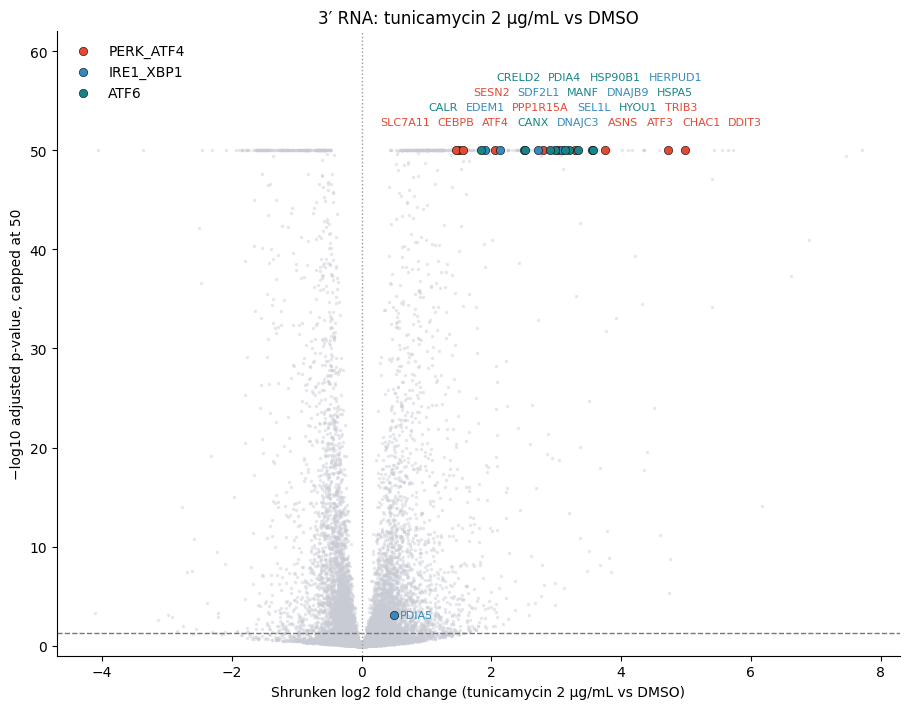

Protein-coding genes tested: 13,418
padj < 0.05: 6,544
Y-axis capped at 50: 462 of 13,418 genes are drawn at the cap.


,baseMean,log2FoldChange,padj,branch
PDIA5,153.465600,0.502299,7.50e-04,IRE1_XBP1
CEBPB,3322.042412,1.451906,< 1e-16,PERK_ATF4
ATF4,13741.274279,1.504753,< 1e-16,PERK_ATF4
SLC7A11,5127.969989,1.563754,< 1e-16,PERK_ATF4
CANX,18464.974895,1.841413,< 1e-16,ATF6
EDEM1,809.822133,1.903015,< 1e-16,IRE1_XBP1
PPP1R15A,401.086605,2.050788,< 1e-16,PERK_ATF4
DNAJC3,1907.331307,2.135501,< 1e-16,IRE1_XBP1
SEL1L,2330.024869,2.501592,< 1e-16,IRE1_XBP1
CALR,32605.987532,2.520423,< 1e-16,ATF6


In [8]:
from dask import delayed
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

pd.set_option("future.infer_string", False)  # required by the current PyDESeq2/pandas combination

rna_var = var_frame(rna)
gene_names = pd.Series(np.asarray(rna.var_names)).astype(str).to_numpy()
protein_coding = rna_var["gene_type"].astype(str).eq("protein_coding").to_numpy()
coding_names = gene_names[protein_coding]

contrast_wells = sorted(layout.loc[layout["condition"].isin(CONTRAST), "Well"])
groups = [(well, layout.loc[layout["Well"].eq(well), "condition"].iloc[0]) for well in contrast_wells]
group_code = np.full(rna.n_obs, -1, dtype=np.int16)
for number, (well, _condition) in enumerate(groups):
    group_code[cell_well == well] = number

cell_counts = pd.DataFrame(
    [{"Well": well, "condition": condition, "cells": int((group_code == i).sum())}
     for i, (well, condition) in enumerate(groups)]
)
if (cell_counts["cells"] < 20).any():
    raise RuntimeError("At least one pseudobulk has fewer than 20 cells.")
display(cell_counts)


def aggregate_sparse_block(block, codes, n_groups, columns):
    """Sum one sparse row chunk on the protein-coding columns."""
    out = np.zeros((n_groups, len(columns)), dtype=np.int64)
    block = block[:, columns]
    for group in np.unique(codes):
        if group >= 0:
            out[group] = np.asarray(block[codes == group].sum(axis=0)).ravel()
    return out


def add_blocks(left, right):
    return left + right


coding_index = np.flatnonzero(protein_coding)
partials = []
start = 0
for block, n_rows in zip(rna.X.to_delayed().ravel(), rna.X.chunks[0]):
    partials.append(delayed(aggregate_sparse_block)(
        block, group_code[start:start + n_rows], len(groups), coding_index
    ))
    start += n_rows
while len(partials) > 1:
    partials = [
        delayed(add_blocks)(partials[i], partials[i + 1]) if i + 1 < len(partials) else partials[i]
        for i in range(0, len(partials), 2)
    ]

pseudobulk_matrix = partials[0].compute()
sample_names = [f"{well}_{condition}" for well, condition in groups]
rna_counts = pd.DataFrame(pseudobulk_matrix, index=sample_names, columns=coding_names)
rna_counts = rna_counts.loc[:, rna_counts.sum(axis=0) >= len(rna_counts) * 5]

rna_design = pd.DataFrame(
    {"condition": [condition for _, condition in groups]},
    index=sample_names,
)
dds = DeseqDataSet(counts=rna_counts, metadata=rna_design, design="~condition", quiet=True)
dds.deseq2()
stats = DeseqStats(dds, contrast=["condition", CONTRAST[0], CONTRAST[1]], quiet=True)
stats.summary()
rna_de = stats.results_df.sort_values("padj")

plot_df = rna_de.dropna(subset=["padj", "log2FoldChange"]).copy()
Y_CAP = 50
PADJ_DISPLAY_FLOOR = 1e-16
plot_df["minus_log10_padj"] = -np.log10(plot_df["padj"].clip(lower=1e-300))
n_above_cap = int((plot_df["minus_log10_padj"] > Y_CAP).sum())
plot_df["y_plot"] = plot_df["minus_log10_padj"].clip(upper=Y_CAP)

gene_to_branch = {gene: branch for branch, genes in UPR_GENE_SETS.items() for gene in genes}
present = [gene for gene in gene_to_branch if gene in plot_df.index]
missing = sorted(set(gene_to_branch) - set(present))
labelled = plot_df.loc[present].copy()
labelled["branch"] = [gene_to_branch[gene] for gene in labelled.index]
labelled["color"] = labelled["branch"].map(BRANCH_COLORS)

fig, ax = plt.subplots(figsize=(9.2, 7.2))
ax.scatter(plot_df["log2FoldChange"], plot_df["y_plot"],
           s=6, c=BACKGROUND_COLOR, alpha=0.45, linewidths=0, rasterized=True)
for branch, color in BRANCH_COLORS.items():
    branch_genes = labelled.loc[labelled["branch"].eq(branch)]
    ax.scatter(branch_genes["log2FoldChange"], branch_genes["y_plot"],
               s=36, c=color, linewidths=0.4, edgecolors="black", zorder=4, label=branch)
ax.axhline(-np.log10(0.05), color="#777", ls="--", lw=1)
ax.axvline(0, color="#999", ls=":", lw=1)
ax.set_ylim(-1, Y_CAP + 12)
ax.set(xlabel="Shrunken log2 fold change (tunicamycin 2 µg/mL vs DMSO)",
       ylabel=f"−log10 adjusted p-value, capped at {Y_CAP}",
       title="3′ RNA: tunicamycin 2 µg/mL vs DMSO")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
label_points(ax, pd.DataFrame({
    "x": labelled["log2FoldChange"].to_numpy(),
    "y": labelled["y_plot"].to_numpy(),
    "label": labelled.index.to_numpy(),
    "color": labelled["color"].to_numpy(),
}))
plt.show()

print(f"Protein-coding genes tested: {len(rna_de):,}")
print(f"padj < 0.05: {(rna_de['padj'] < 0.05).sum():,}")
print(f"Y-axis capped at {Y_CAP}: {n_above_cap:,} of {len(plot_df):,} genes are drawn at the cap.")
if missing:
    print("UPR genes absent from the tested set:", ", ".join(missing))
table = labelled.loc[:, ["baseMean", "log2FoldChange", "padj", "branch"]].sort_values("log2FoldChange")
table["padj"] = [
    "< 1e-16" if value < PADJ_DISPLAY_FLOOR else f"{value:.2e}"
    for value in table["padj"]
]
display(table)


### 6.2 Single-cell UPR score

Cells are sampled evenly across all twelve wells, including untreated and 1 µg/mL, so the score can be compared across the plate. Counts are library-size normalized and log-transformed. The color is `sc.tl.score_genes` on the union of the three UPR lists above. The UMAP layout uses highly variable genes.


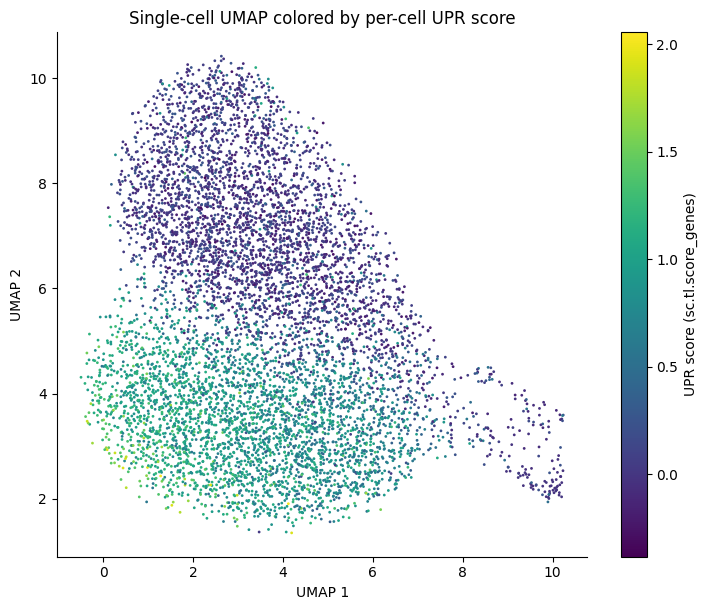

Cells shown: 7,196 (600 per well)
UPR genes in the score: 25
condition
dmso         0.039
tuni_1ug     0.824
tuni_2ug     0.867
untreated    0.041


In [9]:
import scanpy as sc

CELLS_PER_WELL = 600
UMAP_SEED = 42

rng = np.random.default_rng(UMAP_SEED)
sampled = []
for well, indices in pd.Series(np.arange(rna.n_obs)).groupby(cell_well, sort=True).groups.items():
    indices = np.asarray(indices)
    sampled.append(rng.choice(indices, size=min(CELLS_PER_WELL, len(indices)), replace=False))
sampled = np.concatenate(sampled)
rng.shuffle(sampled)

def take_rows(block, local_rows, columns):
    """Materialise one chunk's selected rows on the protein-coding columns."""
    local_rows = np.asarray(local_rows)
    if len(local_rows) == 0:
        return np.zeros((0, len(columns)), dtype=np.float64)
    chosen = block[local_rows][:, columns]
    if hasattr(chosen, "todense"):
        chosen = chosen.todense()
    return np.asarray(chosen)


# Row indices are shuffled, so pull each chunk's rows and restore the sample order.
order = np.argsort(sampled)
sorted_rows = sampled[order]
pieces = []
start = 0
for block, n_rows in zip(rna.X.to_delayed().ravel(), rna.X.chunks[0]):
    local = sorted_rows[(sorted_rows >= start) & (sorted_rows < start + n_rows)] - start
    pieces.append(delayed(take_rows)(block, local, coding_index))
    start += n_rows
import dask
stacked = np.vstack(dask.compute(*pieces))
inverse = np.empty(len(order), dtype=int)
inverse[order] = np.arange(len(order))
sample_counts = stacked[inverse]
kept = sample_counts.sum(axis=1) > 0
sample_counts = sample_counts[kept]
sampled = sampled[kept]
upr_genes = [gene for gene in gene_to_branch if gene in set(coding_names)]
sample = sc.AnnData(sample_counts)
sample.var_names = coding_names
sample.obs["Well"] = cell_well[sampled]
sample.obs["condition"] = cell_condition[sampled]
sample.obs_names_make_unique()

sc.pp.normalize_total(sample, target_sum=1e4)
sc.pp.log1p(sample)
sc.tl.score_genes(sample, upr_genes, score_name="UPR_score", random_state=0)

layout_data = sample.copy()
sc.pp.highly_variable_genes(layout_data, n_top_genes=2000, flavor="seurat")
layout_data = layout_data[:, layout_data.var["highly_variable"]].copy()
sc.pp.scale(layout_data, max_value=10)
sc.tl.pca(layout_data, n_comps=30, random_state=UMAP_SEED)
sc.pp.neighbors(layout_data, n_pcs=30, n_neighbors=15, random_state=UMAP_SEED)
sc.tl.umap(layout_data, random_state=UMAP_SEED, maxiter=200)

fig, ax = plt.subplots(figsize=(7.4, 6.2))
coordinates = layout_data.obsm["X_umap"]
scores = sample.obs["UPR_score"].to_numpy()
points = ax.scatter(
    coordinates[:, 0], coordinates[:, 1], c=scores, s=4, cmap="viridis",
    linewidths=0, rasterized=True,
)
ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Single-cell UMAP colored by per-cell UPR score")
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(points, ax=ax, label="UPR score (sc.tl.score_genes)")
fig.tight_layout()
plt.show()

print(f"Cells shown: {sample.n_obs:,} ({CELLS_PER_WELL} per well)")
print(f"UPR genes in the score: {len(upr_genes)}")
print(sample.obs.groupby("condition", observed=True)["UPR_score"].mean().round(3).to_string())


## Next steps

- Compare the 1 µg/mL arm the same way, or contrast untreated versus DMSO.
- See [`GettingStarted.ipynb`](../GettingStarted.ipynb) for the basics of loading tables.
- Field-level reference: [`spatialdata_object_overview.md`](../../docs/spatialdata_object_overview.md),
  [`anndata_object_overview.md`](../../docs/anndata_object_overview.md).
